###

<h1 style="text-align: center;">
Privacy-Preserving Risk-Based Authentication Using Homomorphic Encryption
</h1>

###

**Motivation**: Account fraud is a common security threat, especially in online services where attackers may attempt to access user accounts using stolen credentials. To detect suspicious login attempts, many companies use Risk-Based Authentication (RBA) systems, which assign a risk score to each login based on factors such as the user’s previous login history, location, device, browser, and access time. However, this process often requires storing and processing sensitive user data in plaintext. Therefore, applying homomorphic encryption can improve privacy by allowing risk evaluation while keeping user information protected.

**Background**

- **Homomorphic Encryption (HE):** a cryptographic technique that allows computations to be performed directly on encrypted data. In this notebook, HE is considered only for the inference stage.

- **Risk-Based Authentication (RBA):** an authentication approach that assigns a risk score to each login attempt based on contextual information such as previous login history, location, device, browser, IP address, and access time. If the risk score is high, the system can require additional verification or block the login attempt.


**Pipeline**

| # | Section | Description |
|---|---------|-------------|
| 1 | Dataset Analysis | Schema, class balance, temporal and geographic characterisation |
| 2 | Feature Engineering | Pair-based delta features: haversine distance, speed, device fingerprint |
| 3 | Train / Test Split | Temporal 80/20 split — prevents temporal data leakage |
| 4 | Balancing Strategy | `scale_pos_weight` for XGBoost — native, no data modification |
| 5 | Model Training | Plaintext XGBClassifier + Concrete-ML FHE XGBClassifier |
| 6 | Validation | Stratified K-Fold CV, ROC/PR curves, feature importance |
| 7 | Testing | Plaintext / FHE-simulate / FHE-execute inference comparison |
| 8 | Artifact Export | Persist models for FastAPI deployment |


In [1]:
# Imports & Configuration
import json
import time
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import seaborn as sns
import xgboost as xgb
from sklearn.metrics import (
    average_precision_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
    accuracy_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
    precision_recall_curve,
)
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='muted', font_scale=1.05)
plt.rcParams['figure.dpi'] = 110

In [2]:
# Paths
DATASET_CSV = (
    Path('/dataset/rba-dataset.csv')
    if Path('/dataset').exists()
    else Path('../database/anomaly-detection-dataset/rba-dataset.csv')
)
MODELS_DIR = (
    Path('/models')
    if Path('/models').exists()
    else Path('../service_provider_app/app/modules/anomaly_detection/models')
)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

In [3]:
# Reproducibility 
SEED = 42
np.random.seed(SEED)

## II. Dataset Analysis

The RBA dataset contains synthesised login-attempt records from a large-scale Norwegian single-sign-on (SSO) service (February 2020 - February 2021).  Features span four categories:
 - network identity (IP, country, ASN)
 - device fingerprint (OS, browser, device type)
 - temporal context (timestamp)
 - authentication outcome


### 1. Load Dataset

Because this notebook is run inside a container with limited memory capacity (24 GB), it is not possible to load all features from the beginning.
We chose to discard the following features:
- User Agent String
- Round-Trip Time (96% of the samples are missing this value)

In [4]:
# Load dataset
LOAD_COLS = [
    'Login Timestamp', 'User ID',
    'Country', 'Region', 'City',
    'Browser Name and Version', 'OS Name and Version', 'Device Type',
    'ASN', 'IP Address', 'Is Attack IP', 'Login Successful', 'Is Account Takeover',
]

NROWS = None
print('Loading dataset ...')
t0 = time.time()
df_raw = pd.read_csv(DATASET_CSV, nrows=NROWS, low_memory=False, usecols=LOAD_COLS)
elapsed = time.time() - t0
print(f'Loaded {len(df_raw):,} rows x {df_raw.shape[1]} columns in {elapsed:.1f}s')
print(f'Memory (raw strings)   : {df_raw.memory_usage(deep=True).sum() / 1e6:,.0f} MB')

# Convert high-cardinality string columns to category dtype.
# Category stores each unique string once; the column itself is a compact integer index.
# Saves ~8-10 GB on 31 M rows, keeping peak allocation well under 20 GB.
for col in ['Country', 'Region', 'City',
            'Browser Name and Version', 'OS Name and Version', 'Device Type',
            'IP Address']:
    df_raw[col] = df_raw[col].astype('category')

print(f'Memory (after category): {df_raw.memory_usage(deep=True).sum() / 1e6:,.0f} MB')
df_raw.head(5)

Loading dataset ...
Loaded 31,269,264 rows x 13 columns in 134.1s
Memory (raw strings)   : 17,640 MB
Memory (after category): 4,013 MB


,Login Timestamp,User ID,IP Address,Country,Region,City,ASN,Browser Name and Version,OS Name and Version,Device Type,Login Successful,Is Attack IP,Is Account Takeover
0,2020-02-03 12:43:30.772,-4324475583306591935,10.0.65.171,NO,-,-,29695,Firefox 20.0.0.1618,iOS 13.4,mobile,False,False,False
1,2020-02-03 12:43:43.549,-4324475583306591935,194.87.207.6,AU,-,-,60117,Chrome Mobile 46.0.2490,Android 4.1,mobile,False,False,False
2,2020-02-03 12:43:55.873,-3284137479262433373,81.167.144.58,NO,Vestland,Urangsvag,29695,Android 2.3.3.2672,iOS 7.1,mobile,True,False,False
3,2020-02-03 12:43:56.180,-4324475583306591935,170.39.78.152,US,-,-,393398,Chrome Mobile WebView 85.0.4183,Android 4.1,mobile,False,False,False
4,2020-02-03 12:43:59.396,-4618854071942621186,10.0.0.47,US,Virginia,Ashburn,398986,Chrome Mobile WebView 85.0.4183,Android 2.2,mobile,False,True,False


### 2. Missing Values

For most features, all values are available. The exceptions are:

- Region: 0.15% missing values
- City: 0.03% missing values

Observation: For the Round-Trip Time feature, 96% of the values were missing. Therefore, it was decided not to load this feature at all in order to save memory.

In [5]:
info = pd.DataFrame({
    'dtype':    df_raw.dtypes.astype(str),
    'non_null': df_raw.notnull().sum(),
    'null_%':   (df_raw.isnull().mean() * 100).round(2),
    'nunique':  df_raw.nunique(),
})
print('=== Schema & Missing Values ===')
print(info.to_string())

=== Schema & Missing Values ===
                             dtype  non_null  null_%   nunique
Login Timestamp             object  31269264    0.00  31269085
User ID                      int64  31269264    0.00   4304857
IP Address                category  31269264    0.00   3512330
Country                   category  31269264    0.00       229
Region                    category  31221855    0.15      2638
City                      category  31260674    0.03     38885
ASN                          int64  31269264    0.00     12955
Browser Name and Version  category  31269264    0.00      4549
OS Name and Version       category  31269264    0.00       653
Device Type               category  31267738    0.00         5
Login Successful              bool  31269264    0.00         2
Is Attack IP                  bool  31269264    0.00         2
Is Account Takeover           bool  31269264    0.00         2


### 3. Class balance

The RBA dataset is highly imbalanced.

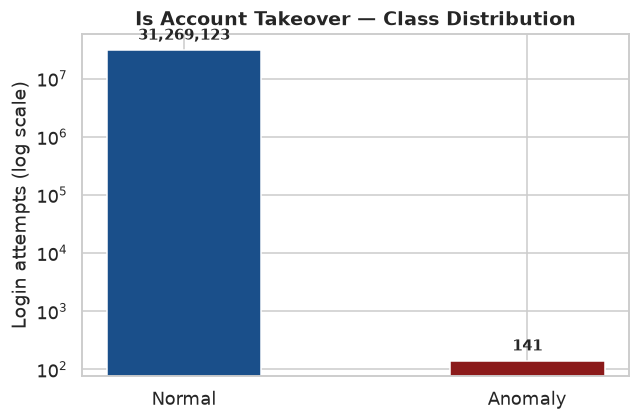

Total logins : 31,269,264
Unique users : 4,304,857



,Count,Share (%)
Class,,
Normal,"31,269,123",99.999549%
Anomaly,141,0.000451%
Total,"31,269,264",100.000000%


Selected label  : Is Account Takeover
Imbalance ratio : 1 : 221,766


In [6]:
# Class balance
from IPython.display import display

n_total = len(df_raw)
n_tak   = df_raw["Is Account Takeover"].isin([True, "True"]).sum()
n_users = df_raw["User ID"].nunique()

LABEL_COL = "Is Account Takeover"
n_pos     = n_tak
n_neg     = n_total - n_tak

# Bar chart — log Y so the tiny anomaly bar is visible alongside 22 M normal logins
fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(
    ["Normal", "Anomaly"],
    [n_neg, n_pos],
    color=["#1a4f8a", "#8b1a1a"],
    width=0.45,
)
ax.set_yscale("log")
ax.set_ylabel("Login attempts (log scale)")
ax.set_title("Is Account Takeover — Class Distribution", fontweight="bold")
for bar, val in zip(bars, [n_neg, n_pos]):
    ax.text(
        bar.get_x() + bar.get_width() / 2, val * 1.3,
        f"{val:,}", ha="center", va="bottom", fontsize=10, fontweight="bold",
    )
plt.tight_layout()
plt.show()

# Summary table — Is Account Takeover only
print(f"Total logins : {n_total:,}")
print(f"Unique users : {n_users:,}")
print()
tbl = pd.DataFrame([
    {"Class": "Normal",  "Count": n_neg,   "Share (%)": round(n_neg / n_total * 100, 6)},
    {"Class": "Anomaly", "Count": n_pos,   "Share (%)": round(n_pos / n_total * 100, 6)},
    {"Class": "Total",   "Count": n_total, "Share (%)": 100.0},
]).set_index("Class")
tbl["Count"]     = tbl["Count"].apply(lambda x: f"{x:,}")
tbl["Share (%)"] = tbl["Share (%)"].apply(lambda x: f"{x:.6f}%")
display(tbl)

print(f"Selected label  : Is Account Takeover")
print(f"Imbalance ratio : 1 : {int(n_neg / max(n_pos, 1)):,}")

### 4. Temporal Distribution of Attacks

Because the memory constraints caused multiple issues, the temporal distribution of attacks was analyzed in order to decide which part of the dataset could be removed optimally.

The goal was to preserve all positive samples, since there were only a few of them anyway. It was observed that after 2020-11, there were no other samples classified as attacks. Therefore, all samples later than 2020-11 were removed.

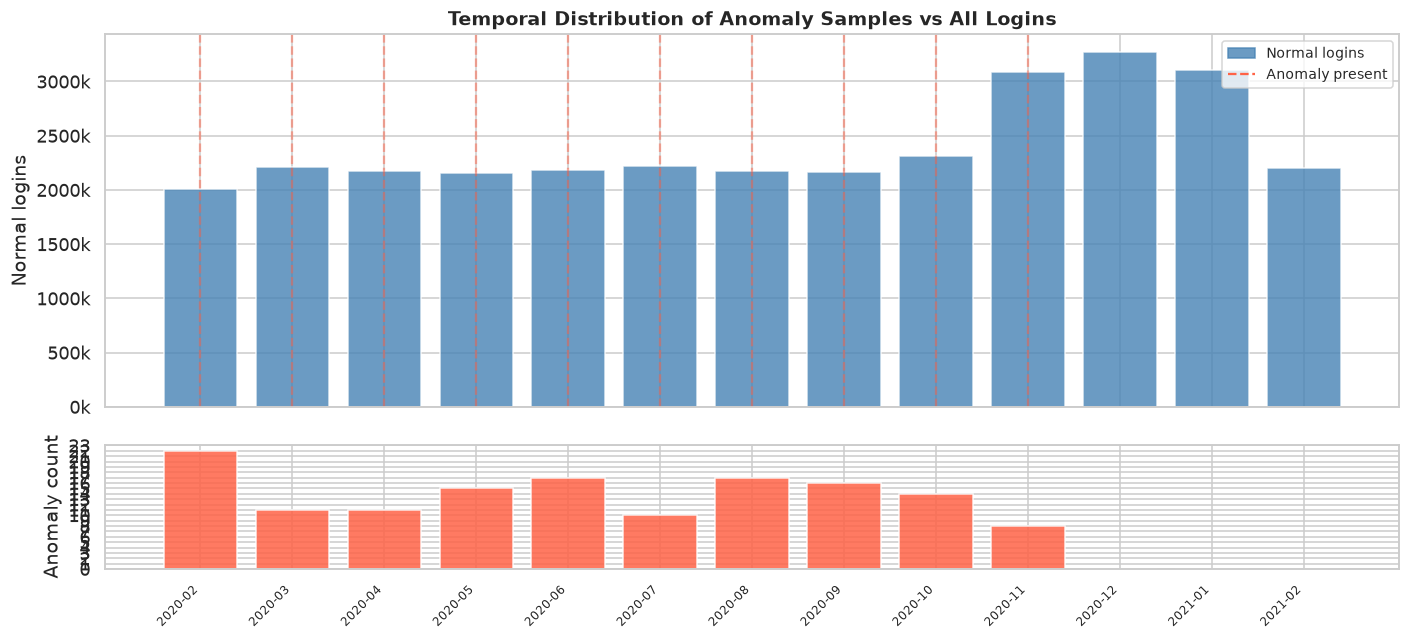

Months containing anomalies:
  2020-02:  22 anomalies  |  dataset position: first 6.4%
  2020-03:  11 anomalies  |  dataset position: first 13.5%
  2020-04:  11 anomalies  |  dataset position: first 20.4%
  2020-05:  15 anomalies  |  dataset position: first 27.3%
  2020-06:  17 anomalies  |  dataset position: first 34.3%
  2020-07:  10 anomalies  |  dataset position: first 41.4%
  2020-08:  17 anomalies  |  dataset position: first 48.4%
  2020-09:  16 anomalies  |  dataset position: first 55.3%
  2020-10:  14 anomalies  |  dataset position: first 62.7%
  2020-11:   8 anomalies  |  dataset position: first 72.6%


In [7]:
# Temporal position of anomaly samples

ts_all      = pd.to_datetime(df_raw['Login Timestamp'], errors='coerce')
is_anomaly  = df_raw['Is Account Takeover'].isin([True, 'True'])

monthly_normal  = ts_all[~is_anomaly].dt.to_period('M').value_counts().sort_index()
monthly_anomaly = ts_all[ is_anomaly].dt.to_period('M').value_counts().sort_index()

all_months   = monthly_normal.index.union(monthly_anomaly.index).sort_values()
normal_vals  = monthly_normal.reindex(all_months,  fill_value=0)
anomaly_vals = monthly_anomaly.reindex(all_months, fill_value=0)
x            = np.arange(len(all_months))
xlabels      = [str(m) for m in all_months]

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 6), sharex=True,
                                gridspec_kw={'height_ratios': [3, 1]})

ax1.bar(x, normal_vals.values, color='steelblue', alpha=0.8)
ax1.set_ylabel('Normal logins')
ax1.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'{int(v/1e3)}k'))
ax1.set_title('Temporal Distribution of Anomaly Samples vs All Logins', fontweight='bold')
for i, v in enumerate(anomaly_vals.values):
    if v > 0:
        ax1.axvline(i, color='tomato', alpha=0.5, linestyle='--', linewidth=1.5)
ax1.legend(handles=[
    plt.Rectangle((0,0),1,1, color='steelblue', alpha=0.8, label='Normal logins'),
    plt.Line2D([0],[0], color='tomato', linestyle='--', lw=1.5, label='Anomaly present'),
], fontsize=9)

ax2.bar(x, anomaly_vals.values, color='tomato', alpha=0.85)
ax2.set_ylabel('Anomaly count')
ax2.set_xticks(x)
ax2.set_xticklabels(xlabels, rotation=45, ha='right', fontsize=8)
ax2.set_yticks(range(0, int(anomaly_vals.max()) + 2))

plt.tight_layout()
plt.show()

print('Months containing anomalies:')
for m, n, a in zip(all_months, normal_vals, anomaly_vals):
    if a > 0:
        pct_dataset = (normal_vals[:list(all_months).index(m)+1].sum()
                       + anomaly_vals[:list(all_months).index(m)+1].sum()) / (normal_vals.sum() + anomaly_vals.sum()) * 100
        print(f'  {m}: {a:3d} anomalies  |  dataset position: first {pct_dataset:.1f}%')

In [8]:
# Trim dataset to rows up to end of 2020-11 (last month containing anomalies)
import gc

_ts    = pd.to_datetime(df_raw['Login Timestamp'], errors='coerce')
before = len(df_raw)
df_raw = df_raw[_ts < '2020-12-01'].reset_index(drop=True)
del _ts
gc.collect()

after = len(df_raw)
print(f'Rows before cutoff  : {before:>12,}')
print(f'Rows after  cutoff  : {after:>12,}  (removed {before - after:,} — {(before-after)/before*100:.1f}%)')
print(f'Anomalies retained  : {df_raw["Is Account Takeover"].isin([True, "True"]).sum()}')

Rows before cutoff  :   31,269,264
Rows after  cutoff  :   22,694,974  (removed 8,574,290 — 27.4%)
Anomalies retained  : 141


### 5. Geographic & Device Characterisation


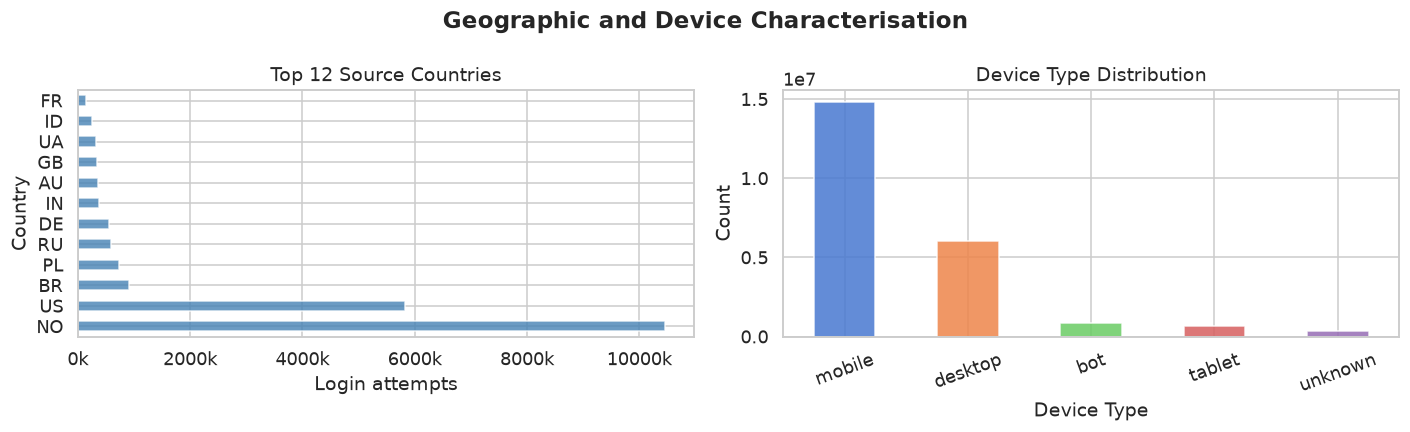

In [9]:
# Geographic & device characterisation
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

top_c = df_raw['Country'].value_counts().head(12)
top_c.plot.barh(ax=axes[0], color='steelblue', alpha=0.8)
axes[0].set_title('Top 12 Source Countries')
axes[0].set_xlabel('Login attempts')
axes[0].xaxis.set_major_formatter(
    mticker.FuncFormatter(lambda x, _: f'{int(x/1e3)}k'))

dt = df_raw['Device Type'].fillna('unknown').value_counts()
dt.plot.bar(ax=axes[1], color=sns.color_palette('muted', len(dt)), alpha=0.85)
axes[1].set_title('Device Type Distribution')
axes[1].set_ylabel('Count')
axes[1].tick_params(axis='x', rotation=20)

plt.suptitle('Geographic and Device Characterisation', fontweight='bold')
plt.tight_layout()
plt.show()

### 6. Login Frequncy per user


=== Login frequency per user ===
count    3536462.00
mean           6.42
std         4957.53
min            1.00
25%            1.00
50%            2.00
75%            4.00
max      9322666.00
Users with >=2 logins : 2,114,776  (59.8%)
Users with >=5 logins : 782,946  (22.1%)
Note: only users with >=2 logins generate pair features.


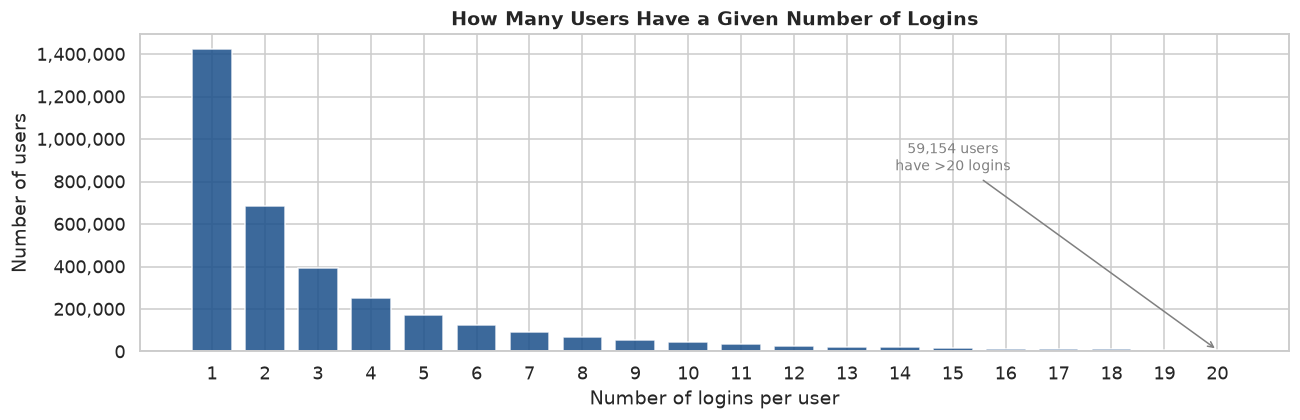

In [10]:
# Login frequency per user
lpu = df_raw.groupby('User ID').size()

print('=== Login frequency per user ===')
print(lpu.describe().round(2).to_string())
print(f'Users with >=2 logins : {(lpu >= 2).sum():,}  ({(lpu >= 2).mean()*100:.1f}%)')
print(f'Users with >=5 logins : {(lpu >= 5).sum():,}  ({(lpu >= 5).mean()*100:.1f}%)')
print('Note: only users with >=2 logins generate pair features.')

CAP     = 20
vc      = lpu.value_counts().sort_index()
vc_show = vc[vc.index <= CAP]
n_tail  = int(vc[vc.index > CAP].sum())

fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(vc_show.index, vc_show.values, color='#1a4f8a', alpha=0.85, width=0.75)
ax.set_xlabel('Number of logins per user')
ax.set_ylabel('Number of users')
ax.set_title('How Many Users Have a Given Number of Logins', fontweight='bold')
ax.set_xticks(range(1, CAP + 1))
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
if n_tail > 0:
    tail_label = f'{n_tail:,} users\nhave >{CAP} logins'
    ax.annotate(
        tail_label,
        xy=(CAP, vc_show.iloc[-1]), xytext=(CAP - 5, vc_show.max() * 0.6),
        arrowprops=dict(arrowstyle='->', color='gray'),
        fontsize=9, color='gray', ha='center',
    )
plt.tight_layout()
plt.show()


## II. Feature Engineering 

### 1. Consecutive Login Pairs

A single login event carries no temporal context. Impossible travel can only be detected by comparing a login event against the immediately preceding login of the same user.

This requires computing pair-level delta features. The dataset is sorted globally by timestamp, meaning all events are in chronological order across all users, but not necessarily per user. Therefore, to create the pairs more easily, the dataset is first sorted by user and then by timestamp.

The first login event of each user is discarded because no previous login is available for comparison.


| Feature | Type | Description |
|---------|------|-------------|
| `distance_km` | continuous | Distance between login countries (haversine on centroids) |
| `speed_kmh` | continuous | Implied travel speed |
| `time_delta_h` | continuous | Elapsed hours since previous login |
| `same_country` | binary | Country unchanged from previous login (1 = same) |
| `same_city` | binary | City unchanged |
| `same_browser` | binary | Browser + version unchanged |
| `same_os` | binary | OS + version unchanged |
| `same_device` | binary | Device type unchanged |
| `hour_of_day` | ordinal | Hour of login (0-23) |
| `is_weekend` | binary | Weekend login flag |


Geographic distance is approximated via **country centroids** - a deliberate simplification that avoids an external geolocation database while preserving the signal for cross-country travel.

In [11]:
# Country centroids + vectorised haversine
COUNTRY_CENTROIDS = {
    'AF':(33.93,67.71),'AL':(41.15,20.17),'DZ':(28.03,1.66),
    'AO':(-11.2,17.87),'AR':(-38.42,-63.62),'AT':(47.52,14.55),
    'AU':(-25.27,133.78),'AZ':(40.14,47.58),'BA':(43.92,17.67),
    'BD':(23.68,90.36),'BE':(50.5,4.47),'BG':(42.73,25.49),
    'BO':(-16.29,-63.59),'BR':(-14.24,-51.93),'BY':(53.71,28.0),
    'CA':(56.13,-106.35),'CH':(46.82,8.23),'CL':(-35.68,-71.54),
    'CN':(35.86,104.2),'CO':(4.57,-74.3),'CZ':(49.82,15.47),
    'DE':(51.17,10.45),'DK':(56.26,9.5),'DO':(18.74,-70.16),
    'EC':(-1.83,-78.18),'EE':(58.6,25.01),'EG':(26.82,30.8),
    'ES':(40.46,-3.75),'ET':(9.15,40.49),'FI':(61.92,25.75),
    'FR':(46.23,2.21),'GB':(55.38,-3.44),'GE':(42.32,43.36),
    'GH':(7.95,-1.02),'GR':(39.07,21.82),'HK':(22.4,114.11),
    'HR':(45.1,16.45),'HU':(47.16,19.5),'ID':(-0.79,113.92),
    'IE':(53.41,-8.24),'IL':(31.05,34.85),'IN':(20.59,78.96),
    'IQ':(33.22,43.68),'IR':(32.43,53.69),'IS':(64.96,-19.02),
    'IT':(41.87,12.57),'JP':(36.2,138.25),'KE':(-0.02,37.91),
    'KR':(35.91,127.77),'KZ':(48.02,66.92),'LT':(55.17,23.88),
    'LV':(56.88,24.6),'MA':(31.79,-7.09),'MD':(47.41,28.37),
    'MX':(23.63,-102.55),'MY':(4.21,101.98),'NG':(9.08,8.68),
    'NL':(52.13,5.29),'NO':(60.47,8.47),'NZ':(-40.9,174.89),
    'PE':(-9.19,-75.02),'PH':(12.88,121.77),'PK':(30.38,69.35),
    'PL':(51.92,19.15),'PT':(39.4,-8.22),'RO':(45.94,24.97),
    'RS':(44.02,21.01),'RU':(61.52,105.32),'SA':(23.89,45.08),
    'SE':(60.13,18.64),'SG':(1.35,103.82),'SK':(48.67,19.7),
    'TH':(15.87,100.99),'TN':(33.89,9.54),'TR':(38.96,35.24),
    'TW':(23.7,121.0),'UA':(48.38,31.17),'US':(37.09,-95.71),
    'UZ':(41.38,64.59),'VN':(14.06,108.28),'ZA':(-30.56,22.94),
}
_LAT = {k: v[0] for k, v in COUNTRY_CENTROIDS.items()}
_LON = {k: v[1] for k, v in COUNTRY_CENTROIDS.items()}

def haversine_vectorised(lat1, lon1, lat2, lon2):
    R = 6371.0
    dlat = np.radians(lat2 - lat1)
    dlon = np.radians(lon2 - lon1)
    a = (np.sin(dlat / 2) ** 2
         + np.cos(np.radians(lat1)) * np.cos(np.radians(lat2))
         * np.sin(dlon / 2) ** 2)
    return 2.0 * R * np.arcsin(np.sqrt(np.clip(a, 0.0, 1.0)))


In [12]:
FEATURE_COLS = [
    'distance_km', 'speed_kmh', 'time_delta_h',
    'same_country', 'same_region', 'same_city',
    'same_browser', 'same_os', 'same_device', 'same_asn',
    'hour_of_day', 'is_weekend',
    'is_attack_ip', 'prev_is_attack_ip', 'prev_login_failed',
    'same_ip', 'same_ip_prefix',
    'is_first_login',
]

MAX_SPEED_KMH = 50_000  # physical cap: slightly above commercial aircraft speed

def engineer_pair_features(df: pd.DataFrame, label_col: str) -> pd.DataFrame:
    df = df.copy()
    df['Login Timestamp'] = pd.to_datetime(df['Login Timestamp'], errors='coerce')
    df[label_col] = df[label_col].isin([True, 'True']).astype(np.int8)

    # Sort per user chronologically so shift(1) always gives the previous login
    # of the same user. The raw dataset is globally sorted by timestamp but users
    # are interleaved across rows.
    df = df.sort_values(['User ID', 'Login Timestamp']).reset_index(drop=True)

    # Shift each relevant column by 1 within each user group to obtain the
    # predecessor login's values. The temporary '_p_*' columns are dropped at the end.
    grp = df.groupby('User ID', sort=False)
    for col in ['Login Timestamp', 'Country', 'Region', 'City',
                'Browser Name and Version', 'OS Name and Version', 'Device Type',
                'ASN', 'IP Address', 'Is Attack IP', 'Login Successful']:
        df[f'_p_{col}'] = grp[col].shift(1)

    # Mark first-login rows (no predecessor) before filling.
    # Kept as a feature so the model can learn that first-login events have
    # a different risk profile from subsequent logins.
    first_login_mask = df['_p_Login Timestamp'].isna()
    df['is_first_login'] = first_login_mask.astype(np.int8)

    # Fill first-login predecessors with neutral defaults instead of dropping rows:
    # - timestamp  -> current login time  (time_delta_h = 0)
    # - location / device / network -> current values  (same_* = 1, distance = 0)
    # - attack IP  -> False   (no prior threat signal)
    # - login success -> True (no prior failed login)
    df['_p_Login Timestamp'] = df['_p_Login Timestamp'].fillna(df['Login Timestamp'])
    for col in ['Country', 'Region', 'City', 'Browser Name and Version',
                'OS Name and Version', 'Device Type', 'ASN', 'IP Address']:
        df[f'_p_{col}'] = df[f'_p_{col}'].fillna(df[col])
    df['_p_Is Attack IP']    = df['_p_Is Attack IP'].fillna(False)
    df['_p_Login Successful'] = df['_p_Login Successful'].fillna(True)

    # --- Temporal features ---
    # Elapsed time since the previous login by the same user.
    elapsed_s = (df['Login Timestamp'] - df['_p_Login Timestamp']
                 ).dt.total_seconds().clip(lower=0)
    df['time_delta_h'] = elapsed_s / 3600.0
    # Hour-of-day context: attacks may cluster at unusual hours.
    df['hour_of_day']  = df['Login Timestamp'].dt.hour
    # Weekend flag: weekends have different baseline login patterns.
    df['is_weekend']   = (df['Login Timestamp'].dt.dayofweek >= 5).astype(np.int8)

    # --- Location consistency features ---
    # Detect whether the user's apparent geographic location changed between
    # consecutive logins (country -> region -> city, coarse to fine).
    df['same_country'] = (df['Country'] == df['_p_Country']).astype(np.int8)
    df['same_region']  = (df['Region']  == df['_p_Region']).astype(np.int8)
    df['same_city']    = (df['City']    == df['_p_City']).astype(np.int8)

    # --- Device fingerprint consistency features ---
    # Changes in browser, OS, or device type can indicate a different device
    # or a credential-sharing / account-takeover scenario.
    df['same_browser'] = (
        df['Browser Name and Version'] == df['_p_Browser Name and Version']
    ).astype(np.int8)
    df['same_os'] = (
        df['OS Name and Version'] == df['_p_OS Name and Version']
    ).astype(np.int8)
    df['same_device'] = (
        df['Device Type'] == df['_p_Device Type']
    ).astype(np.int8)
    # ASN (Autonomous System Number) identifies the network operator;
    # a change suggests a different ISP, mobile carrier, or VPN.
    df['same_asn'] = (df['ASN'] == df['_p_ASN']).astype(np.int8)

    # --- Threat-intelligence features ---
    # Whether the current or previous IP appears on the attack-IP blocklist.
    df['is_attack_ip']      = df['Is Attack IP'].isin([True, 'True']).astype(np.int8)
    df['prev_is_attack_ip'] = df['_p_Is Attack IP'].isin([True, 'True']).astype(np.int8)
    # A failed previous login often precedes credential-stuffing takeovers.
    df['prev_login_failed'] = (~df['_p_Login Successful'].isin([True, 'True'])).astype(np.int8)

    # --- IP-level continuity features ---
    # Convert category dtype to str for reliable cross-category equality comparison.
    ip_cur  = df['IP Address'].astype(str)
    ip_prev = df['_p_IP Address'].astype(str)
    # Exact IP match: same device/session on the same network.
    df['same_ip']        = (ip_cur == ip_prev).astype(np.int8)
    # /24 prefix match: same local subnet even when the IP rotated (e.g. DHCP).
    df['same_ip_prefix'] = (
        ip_cur.str.rsplit('.', n=1).str[0] == ip_prev.str.rsplit('.', n=1).str[0]
    ).astype(np.int8)

    # --- Geographic distance and implied travel speed ---
    # Distance is approximated via country centroids -- avoids an external
    # geolocation database while preserving the cross-country travel signal.
    lat_cur  = df['Country'].map(_LAT).values.astype(float)
    lon_cur  = df['Country'].map(_LON).values.astype(float)
    lat_prev = df['_p_Country'].map(_LAT).values.astype(float)
    lon_prev = df['_p_Country'].map(_LON).values.astype(float)

    dist = haversine_vectorised(lat_cur, lon_cur, lat_prev, lon_prev)
    # Assign 0 km when either country is absent from the centroids dictionary.
    df['distance_km'] = np.where(np.isnan(lat_cur) | np.isnan(lat_prev), 0.0, dist)
    # Implied travel speed; capped at MAX_SPEED_KMH to handle near-simultaneous
    # logins from geographically distant IPs (shared accounts / VPN switching).
    df['speed_kmh'] = np.where(
        df['time_delta_h'] > 0,
        np.minimum(df['distance_km'] / df['time_delta_h'], MAX_SPEED_KMH),
        np.where(df['distance_km'] > 0, float(MAX_SPEED_KMH), 0.0),
    )

    # Remove all temporary predecessor columns before returning.
    return df.drop(columns=[c for c in df.columns if c.startswith('_p_')])

The new engineered features are added as extensions to the dataset:

In [13]:
import gc

print(f'df_raw  : {df_raw.memory_usage(deep=True).sum() / 1e6:,.0f} MB  ({df_raw.shape[1]} columns)')
print('\nEngineering pair features ...')
t0 = time.time()
df = engineer_pair_features(df_raw, LABEL_COL)
del df_raw
gc.collect()
print(f'Done in {time.time()-t0:.1f}s  |  shape: {df.shape}')

n_pos = int((df[LABEL_COL] == 1).sum())
n_neg = int((df[LABEL_COL] == 0).sum())
n_tot = len(df)
print(f'\nPost-engineering class distribution:')
print(f'  Normal  : {n_neg:>10,}  ({n_neg/n_tot*100:.3f}%)')
print(f'  Anomaly : {n_pos:>10,}  ({n_pos/n_tot*100:.4f}%)')

if n_pos < 10:
    raise RuntimeError(
        f'Only {n_pos} anomalies after pair engineering. '
        f'Set NROWS=None to load the full dataset.')

print('\nFeature statistics:')
df[FEATURE_COLS].describe().round(3)

df_raw  : 3,018 MB  (13 columns)

Engineering pair features ...
Done in 78.8s  |  shape: (22694974, 31)

Post-engineering class distribution:
  Normal  : 22,694,833  (99.999%)
  Anomaly :        141  (0.0006%)

Feature statistics:


,distance_km,speed_kmh,time_delta_h,same_country,same_region,same_city,same_browser,same_os,same_device,same_asn,hour_of_day,is_weekend,is_attack_ip,prev_is_attack_ip,prev_login_failed,same_ip,same_ip_prefix,is_first_login
count,2.269497e+07,2.269497e+07,2.269497e+07,2.269497e+07,2.269497e+07,2.269497e+07,2.269497e+07,2.269497e+07,2.269497e+07,2.269497e+07,2.269497e+07,2.269497e+07,2.269497e+07,2.269497e+07,2.269497e+07,2.269497e+07,2.269497e+07,2.269497e+07
mean,2.424293e+03,1.534003e+04,2.033540e+02,6.840000e-01,5.770000e-01,5.640000e-01,4.700000e-01,5.350000e-01,7.360000e-01,5.890000e-01,1.226800e+01,2.590000e-01,9.400000e-02,7.600000e-02,5.180000e-01,4.130000e-01,4.420000e-01,1.560000e-01
std,4.206910e+03,2.305529e+04,6.472540e+02,4.650000e-01,4.940000e-01,4.960000e-01,4.990000e-01,4.990000e-01,4.410000e-01,4.920000e-01,5.603000e+00,4.380000e-01,2.920000e-01,2.650000e-01,5.000000e-01,4.920000e-01,4.970000e-01,3.630000e-01
min,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,8.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
50%,0.000000e+00,0.000000e+00,1.000000e-03,1.000000e+00,1.000000e+00,1.000000e+00,0.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.200000e+01,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
75%,4.821179e+03,5.000000e+04,1.444100e+01,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.700000e+01,1.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,0.000000e+00
max,1.989040e+04,5.000000e+04,7.227927e+03,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,2.300000e+01,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00


=== Mean feature values: normal vs anomaly ===
                   Normal (mean)  Anomaly (mean)  Ratio A/N
distance_km             2424.295        2196.593       0.91
speed_kmh              15340.112        2133.505       0.14
time_delta_h             203.353         477.633       2.35
same_country               0.684           0.489       0.71
same_region                0.577           0.546       0.95
same_city                  0.564           0.546       0.97
same_browser               0.470           0.518       1.10
same_os                    0.535           0.645       1.21
same_device                0.736           0.759       1.03
same_asn                   0.589           0.461       0.78
hour_of_day               12.268          13.085       1.07
is_weekend                 0.259           0.277       1.07
is_attack_ip               0.094           0.546       5.81
prev_is_attack_ip          0.076           0.142       1.87
prev_login_failed          0.518           0.156     

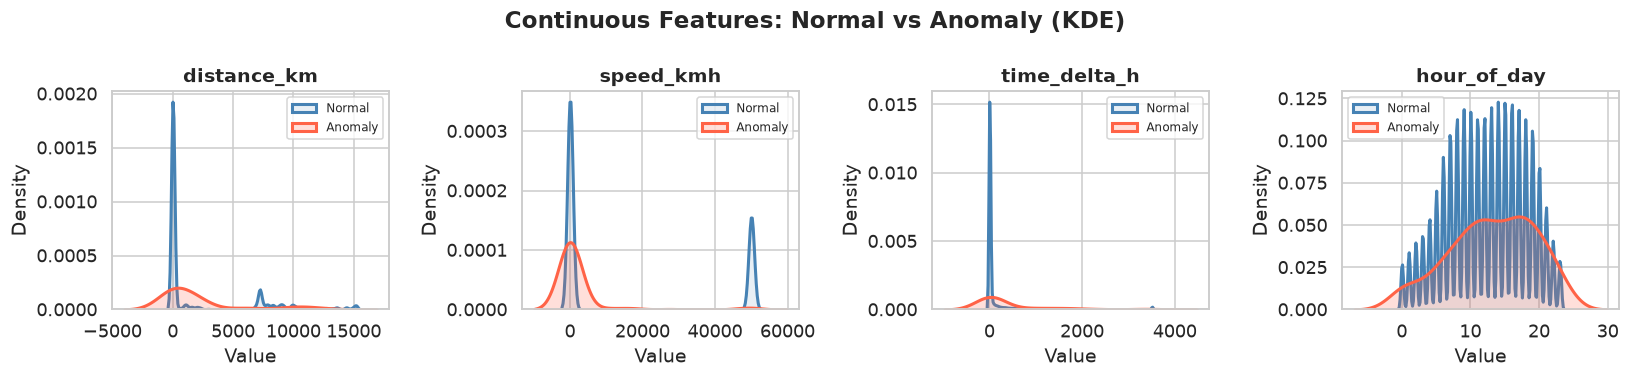

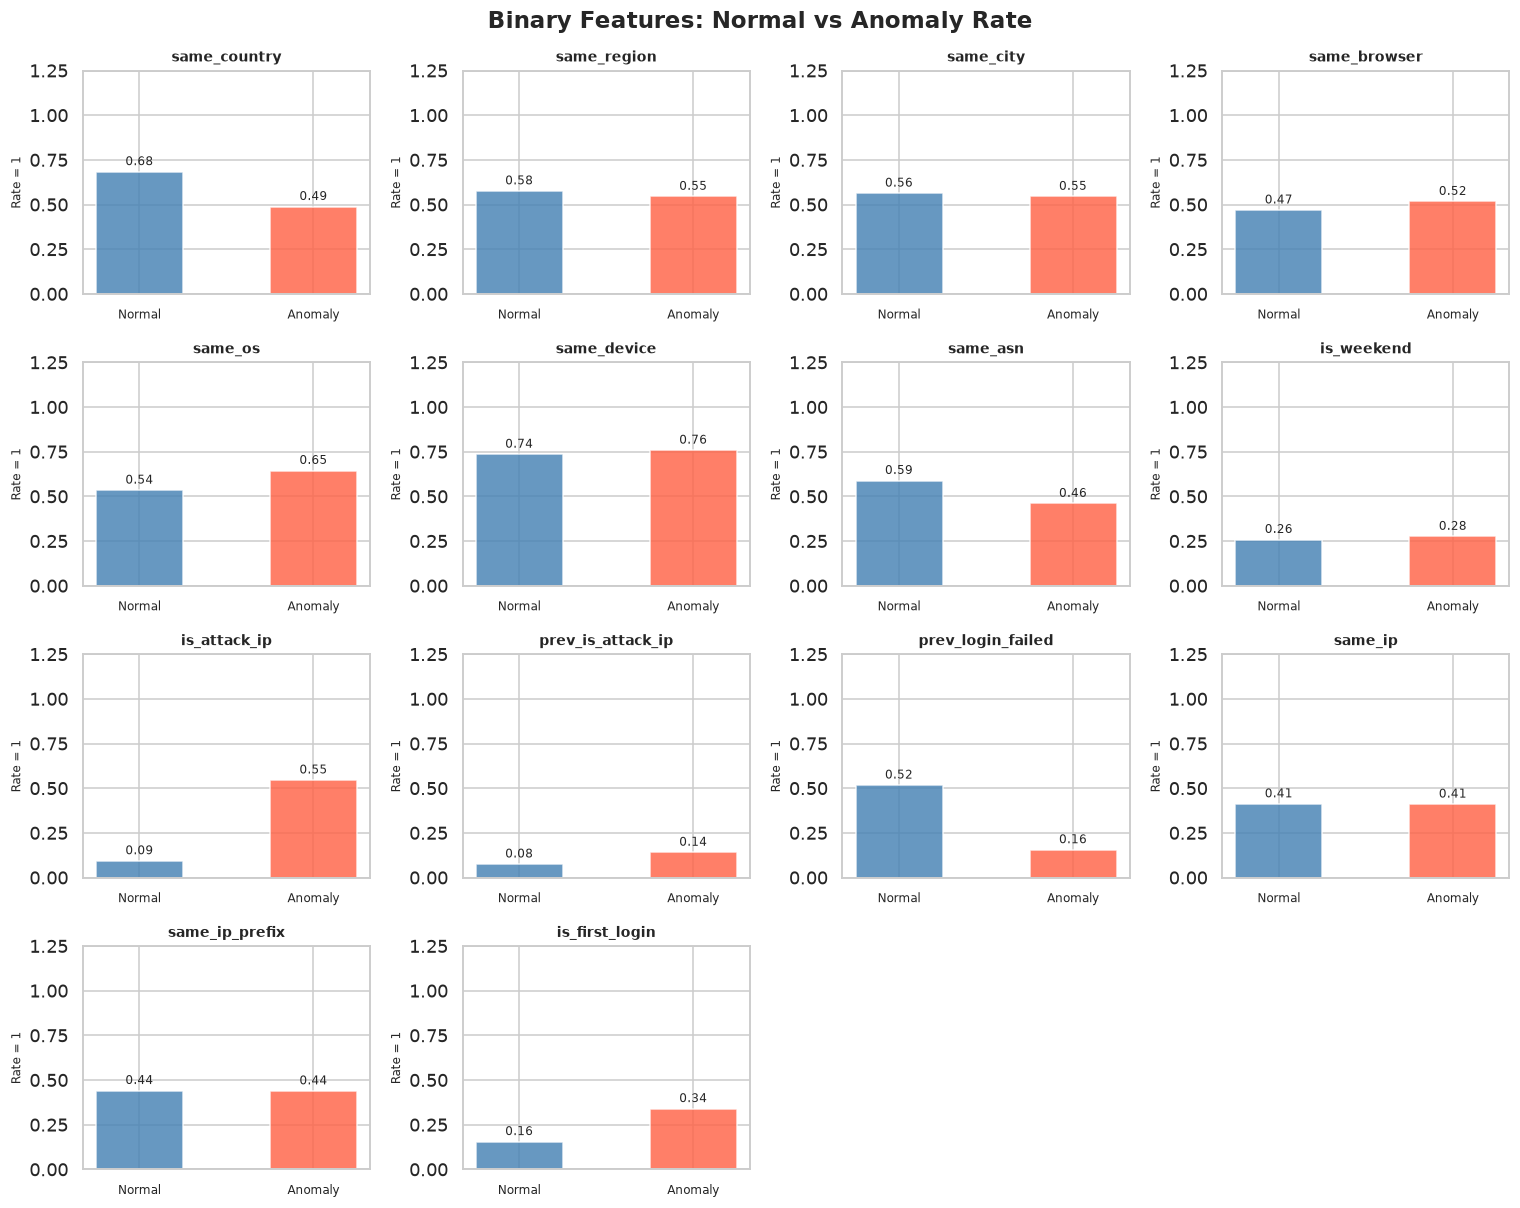

In [14]:
# Feature distributions: normal vs anomaly
df_pos = df[df[LABEL_COL] == 1]
df_neg = df[df[LABEL_COL] == 0]

# Mean comparison table
cmp = pd.DataFrame({
    'Normal (mean)':  df_neg[FEATURE_COLS].mean(),
    'Anomaly (mean)': df_pos[FEATURE_COLS].mean(),
}).round(3)
cmp['Ratio A/N'] = (
    cmp['Anomaly (mean)'] / cmp['Normal (mean)'].replace(0, np.nan)
).round(2)
print('=== Mean feature values: normal vs anomaly ===')
print(cmp.to_string())

# --- Continuous features: KDE overlay -- 2 lines per plot ---
CONTINUOUS_FEATS = ['distance_km', 'speed_kmh', 'time_delta_h', 'hour_of_day']
BINARY_FEATS     = [f for f in FEATURE_COLS if f not in CONTINUOUS_FEATS]

fig, axes = plt.subplots(1, len(CONTINUOUS_FEATS), figsize=(15, 3.5))
for ax, feat in zip(axes, CONTINUOUS_FEATS):
    cap = df[feat].quantile(0.99)
    sns.kdeplot(df_neg[feat].clip(upper=cap), ax=ax, color='steelblue',
                fill=True, alpha=0.12, linewidth=2, label='Normal')
    sns.kdeplot(df_pos[feat].clip(upper=cap), ax=ax, color='tomato',
                fill=True, alpha=0.20, linewidth=2, label='Anomaly')
    ax.set_title(feat, fontweight='bold')
    ax.set_xlabel('Value')
    ax.set_ylabel('Density')
    ax.legend(fontsize=8)
plt.suptitle('Continuous Features: Normal vs Anomaly (KDE)', fontweight='bold')
plt.tight_layout()
plt.show()

# --- Binary features: one subplot per feature, 2 bars (normal vs anomaly rate) ---
n_cols = 4
n_rows = (len(BINARY_FEATS) + n_cols - 1) // n_cols
fig, axes = plt.subplots(n_rows, n_cols, figsize=(14, n_rows * 2.8))
for i, feat in enumerate(BINARY_FEATS):
    ax = axes.flat[i]
    norm_rate = df_neg[feat].mean()
    anom_rate = df_pos[feat].mean()
    bars = ax.bar(['Normal', 'Anomaly'], [norm_rate, anom_rate],
                  color=['steelblue', 'tomato'], alpha=0.82, width=0.5)
    for bar, v in zip(bars, [norm_rate, anom_rate]):
        ax.text(bar.get_x() + bar.get_width() / 2, v + 0.02,
                f'{v:.2f}', ha='center', va='bottom', fontsize=8)
    ax.set_title(feat, fontweight='bold', fontsize=9)
    ax.set_ylim(0, 1.25)
    ax.set_ylabel('Rate = 1', fontsize=8)
    ax.tick_params(axis='x', labelsize=8)

for j in range(len(BINARY_FEATS), len(axes.flat)):
    axes.flat[j].set_visible(False)

plt.suptitle('Binary Features: Normal vs Anomaly Rate', fontweight='bold')
plt.tight_layout()
plt.show()

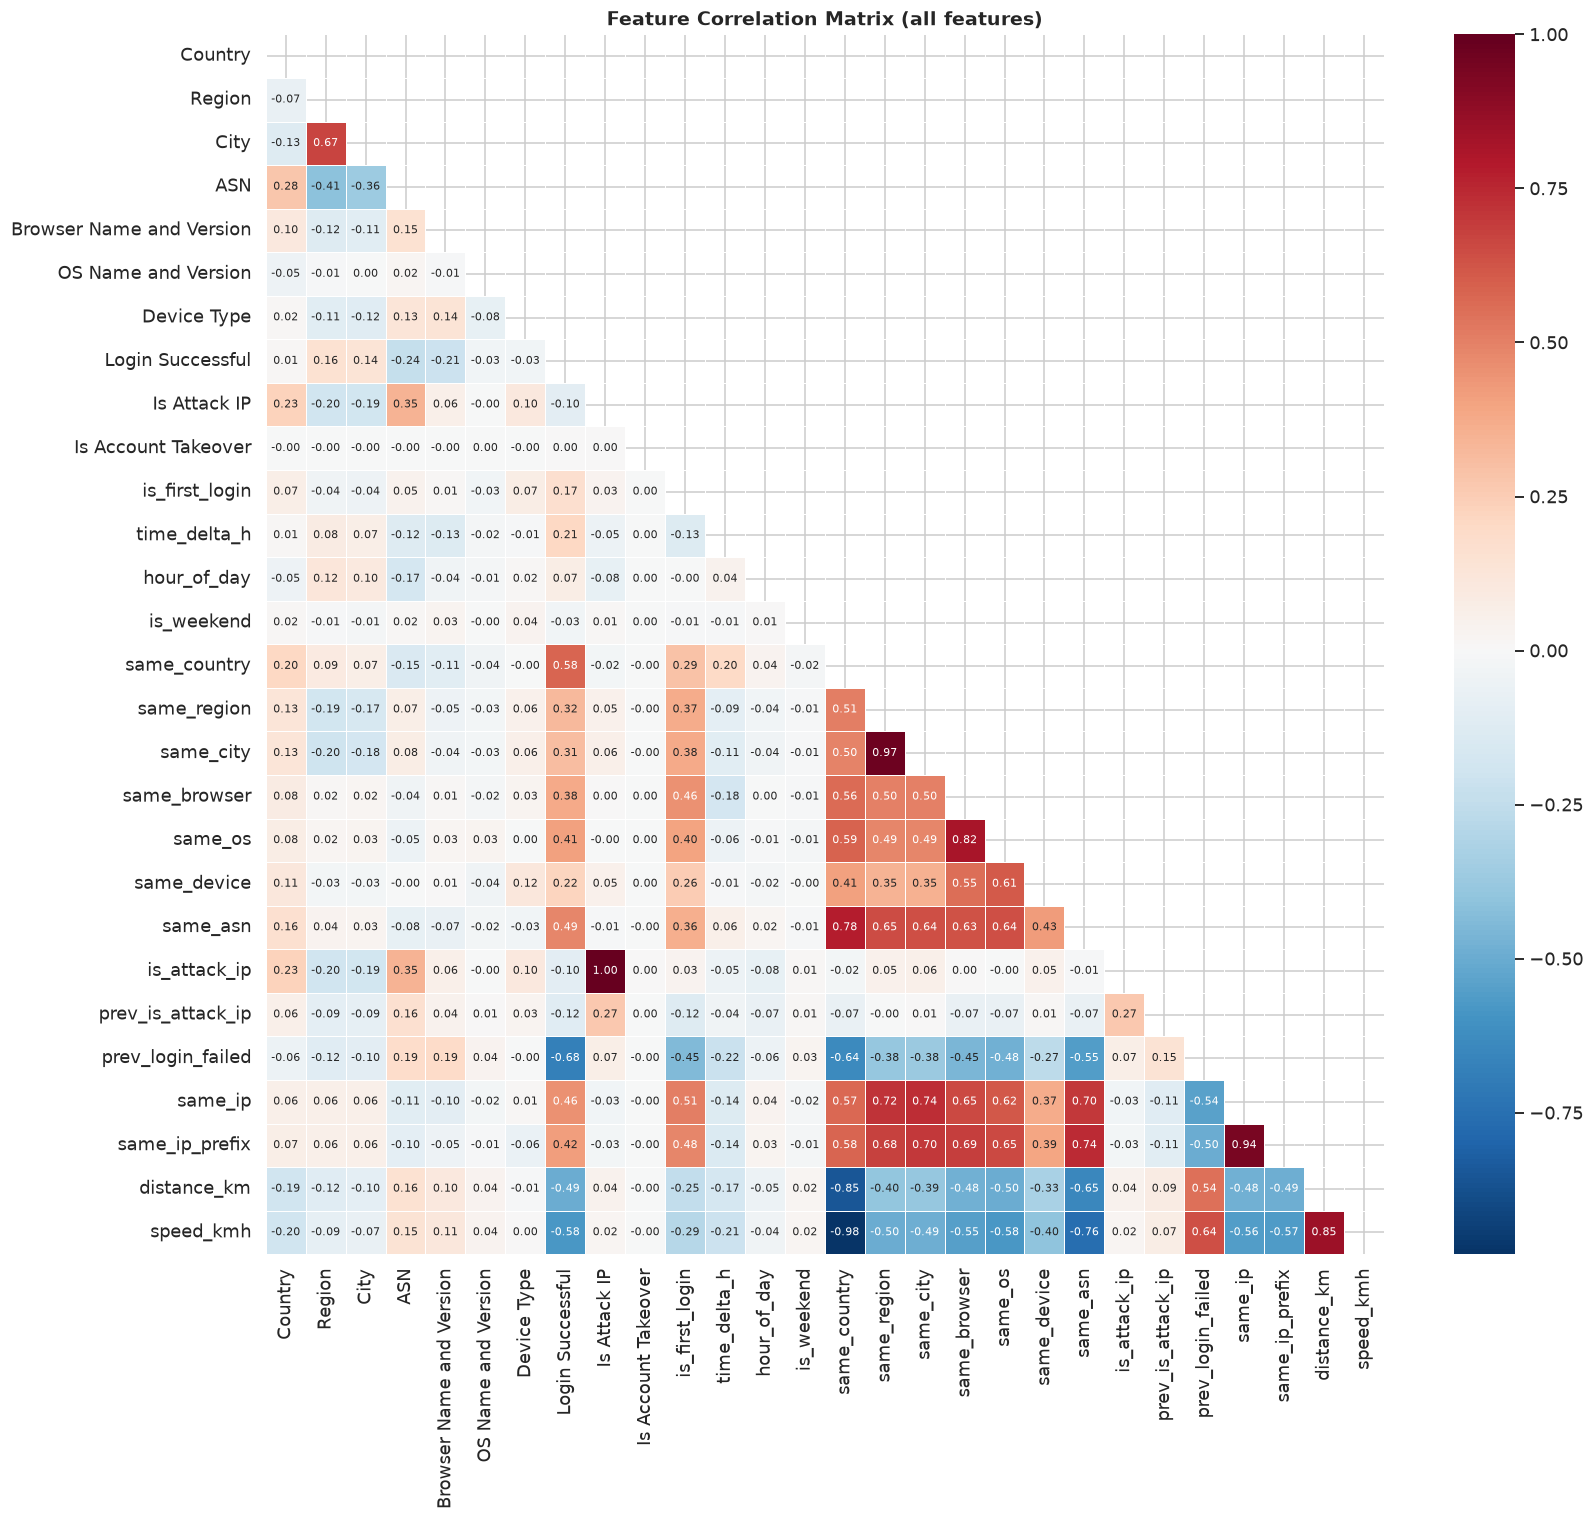

In [15]:
# Correlation analysis -- all features present in the dataframe
# High-cardinality identifier columns (Login Timestamp, User ID, IP Address) are excluded -- they carry no signal for anomaly detection.

SKIP_COLS = {'Login Timestamp', 'User ID', 'IP Address'}

df_corr = pd.DataFrame(index=df.index)
for col in df.columns:
    if col in SKIP_COLS:
        continue
    s = df[col]
    if hasattr(s, 'cat'):
        df_corr[col] = s.cat.codes          # -1 for NaN categories
    elif s.dtype == bool or str(s.dtype) == 'object':
        df_corr[col] = s.astype(np.int8)
    else:
        df_corr[col] = s

corr = df_corr.corr()
n = len(corr)
fig, ax = plt.subplots(figsize=(max(9, n * 0.55), max(7, n * 0.50)))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r',
            center=0, ax=ax, linewidths=0.4, annot_kws={'size': 7})
ax.set_title('Feature Correlation Matrix (all features)', fontweight='bold')
plt.tight_layout(); plt.show()

Taking a closer look at the corraltions with *is_account_takeover*:

In [16]:
print(f'Top correlations with "{LABEL_COL}":')
lc = corr[LABEL_COL].drop(LABEL_COL).sort_values(key=abs, ascending=False)
for feat, val in lc.items():
    bar  = chr(9608) * max(1, int(abs(val) * 30))
    sign = '+' if val > 0 else '-'
    print(f'  {feat:<30} {sign}{abs(val):.4f}  {bar}')

Top correlations with "Is Account Takeover":
  is_attack_ip                   +0.0039  █
  Is Attack IP                   +0.0039  █
  Login Successful               +0.0028  █
  Device Type                    -0.0022  █
  prev_login_failed              -0.0018  █
  Browser Name and Version       -0.0016  █
  speed_kmh                      -0.0014  █
  is_first_login                 +0.0013  █
  time_delta_h                   +0.0011  █
  same_country                   -0.0010  █
  Region                         -0.0010  █
  Country                        -0.0008  █
  same_asn                       -0.0006  █
  prev_is_attack_ip              +0.0006  █
  same_os                        +0.0006  █
  hour_of_day                    +0.0004  █
  same_browser                   +0.0002  █
  City                           -0.0002  █
  same_region                    -0.0002  █
  distance_km                    -0.0001  █
  same_device                    +0.0001  █
  OS Name and Version          

## III. Train / Test Split

A **temporal (chronological) split** is used: the earliest 80% of login pairs form the training set;
the most recent 20% form the test set.


In [17]:
# 3. Train / Test split

SPLIT_RATIO        = 0.80
MIN_TEST_ANOMALIES = 5

# Step 1: extract only needed columns, free the full df immediately
df_slim = df[FEATURE_COLS + [LABEL_COL, 'Login Timestamp']].copy()
del df
gc.collect()
print(f'df slimmed: {df_slim.memory_usage(deep=True).sum() / 1e6:.0f} MB')

# Step 2: sort on the slim frame
df_sorted = df_slim.sort_values('Login Timestamp').reset_index(drop=True)
del df_slim
gc.collect()

# Step 3: extract numpy arrays, free the sorted frame
split_idx = int(len(df_sorted) * SPLIT_RATIO)
X_all = df_sorted[FEATURE_COLS].values.astype(np.float32)
y_all = df_sorted[LABEL_COL].values.astype(np.int8)
del df_sorted
gc.collect()

# Step 4: attempt temporal split
X_train_raw, X_test_raw = X_all[:split_idx], X_all[split_idx:]
y_train,     y_test      = y_all[:split_idx], y_all[split_idx:]
split_method = 'Temporal (chronological)'

if int(y_test.sum()) < MIN_TEST_ANOMALIES:
    print(f'[NOTE] Temporal split produced only {int(y_test.sum())} test anomalies.')
    print(f'       "{LABEL_COL}" events are temporally concentrated in the')
    print(f'       first {SPLIT_RATIO*100:.0f}% of the observation period.')
    print(f'       Falling back to stratified random split (seed={SEED}).\n')
    X_train_raw, X_test_raw, y_train, y_test = train_test_split(
        X_all, y_all,
        test_size=1.0 - SPLIT_RATIO,
        stratify=y_all,
        random_state=SEED,
    )
    split_method = 'Stratified random (fallback — label temporally concentrated)'

del X_all, y_all
gc.collect()

print('=== Split Summary ===')
print(f'Method          : {split_method}')
print(f'{"":28} {"Train":>12} {"Test":>12}')
print(f'{"Samples":<28} {len(X_train_raw):>12,} {len(X_test_raw):>12,}')
print(f'{"Anomalies":<28} {int(y_train.sum()):>12,} {int(y_test.sum()):>12,}')
print(f'{"Positive rate":<28} {y_train.mean()*100:>11.4f}% {y_test.mean()*100:>11.4f}%')

df slimmed: 1157 MB
=== Split Summary ===
Method          : Temporal (chronological)
                                    Train         Test
Samples                        18,155,979    4,538,995
Anomalies                             125           16
Positive rate                     0.0007%      0.0004%


## 4. Class Imbalance & Balancing Strategy

Account takeover events are extremely rare (< 0.01% of all login attempts).  Standard classifiers
trained on such imbalanced data tend to predict the majority class exclusively, achieving high
accuracy while being useless for anomaly detection.

### Strategies Evaluated
| Strategy | Mechanism | XGBoost-native | Notes |
|----------|-----------|---------------|-------|
| `scale_pos_weight` | Upweights positive-class gradient updates | Yes | **Selected** — no data modification |
| SMOTE | Synthetic minority oversampling | No | Not used — combining with scale_pos_weight double-counts the minority class |
| Random undersampling | Discard majority samples | No | Information loss |
| `sample_weight` | Per-sample loss scaling | Via wrapper | Equivalent to scale_pos_weight |

**Selected:** `scale_pos_weight = n_negative / n_positive`

XGBoost's `scale_pos_weight` rescales the gradient contribution of positive-class samples,
balancing gradient updates without altering the dataset.  This is the approach recommended
in the XGBoost documentation for binary imbalanced classification.
The final precision / recall operating point is controlled separately via a calibrated
decision threshold (Section 6b).

=== Training Set Class Balance ===
Negative samples : 18,155,854
Positive samples :        125
Imbalance ratio  :     2000.0 : 1
scale_pos_weight :    2000.00


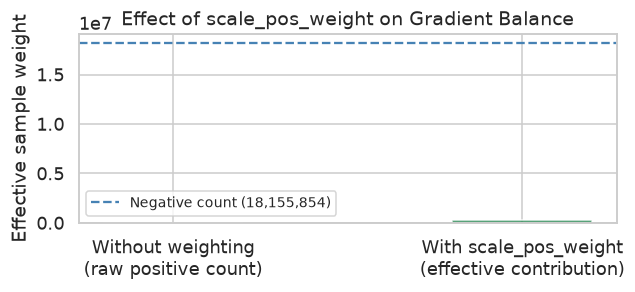

In [18]:
# 4. Compute scale_pos_weight from the raw training set
n_neg_train = int((y_train == 0).sum())
n_pos_train = int((y_train == 1).sum())
pos_weight  = float(n_neg_train) / float(n_pos_train)
pos_weight  = min(pos_weight, 2000.0)  # cap: extreme ratios destabilise XGBoost

print('=== Training Set Class Balance ===')
print(f'Negative samples : {n_neg_train:>10,}')
print(f'Positive samples : {n_pos_train:>10,}')
print(f'Imbalance ratio  : {pos_weight:>10.1f} : 1')
print(f'scale_pos_weight : {pos_weight:>10.2f}')

fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(['Without weighting\n(raw positive count)',
        'With scale_pos_weight\n(effective contribution)'],
       [n_pos_train, n_pos_train * pos_weight],
       color=['tomato', 'seagreen'], alpha=0.8, width=0.4)
ax.axhline(n_neg_train, color='steelblue', linestyle='--', linewidth=1.5,
           label=f'Negative count ({n_neg_train:,})')
ax.set_ylabel('Effective sample weight')
ax.set_title('Effect of scale_pos_weight on Gradient Balance')
ax.legend(fontsize=9)
plt.tight_layout(); plt.show()

## V. Model Training

Two XGBoost classifiers are trained on the same preprocessed (scaled) features:

**5a. Plaintext XGBClassifier** (`xgboost.XGBClassifier`)
Standard gradient-boosted tree ensemble; serves as the accuracy ceiling and latency baseline.
Uses 200 trees with depth 5 — optimised for accuracy.

**5b. FHE XGBClassifier** (`concrete.ml.sklearn.XGBClassifier`)
Concrete-ML quantisation-aware variant compiled to an FHE Boolean circuit.
Uses 30 trees with depth 4 and 6-bit quantisation — deliberately conservative
to keep the compiled circuit small (fewer PBS operations per inference).

> `StandardScaler` is applied before training.  Although tree-based models are
> scale-invariant, the scaler is retained for compatibility with the deployment pipeline
> (`ml_model.py` always scales inputs before calling the model).

In [19]:
# 5a. StandardScaler + plaintext XGBClassifier
scaler    = StandardScaler()
X_train   = scaler.fit_transform(X_train_raw)
X_test    = scaler.transform(X_test_raw)

# Raw arrays no longer needed — scaled versions are used for everything downstream
del X_train_raw, X_test_raw
gc.collect()

PT_PARAMS = dict(
    n_estimators     = 300,
    max_depth        = 5,
    learning_rate    = 0.05,
    subsample        = 0.8,
    colsample_bytree = 0.8,
    min_child_weight = 1,      # allow splits on individual anomaly samples
    gamma            = 0.0,    # no minimum loss reduction requirement
    reg_lambda       = 1.0,    # standard L2 regularisation
    scale_pos_weight = pos_weight,
    eval_metric      = 'aucpr',
    random_state     = SEED,
    n_jobs           = -1,
    verbosity        = 0,
)

print('Training plaintext XGBClassifier ...')
pt_xgb = xgb.XGBClassifier(**PT_PARAMS)
t0 = time.time()
pt_xgb.fit(X_train, y_train)
print(f'Trained in {time.time()-t0:.1f}s')
print(f'Trees: {PT_PARAMS["n_estimators"]}  |  Max depth: {PT_PARAMS["max_depth"]}')

Training plaintext XGBClassifier ...
Trained in 601.2s
Trees: 300  |  Max depth: 5


In [20]:
# 5b. Concrete-ML FHE XGBClassifier + compile
#
# The FHE model uses a deliberate stratified subsample of the training set.
# Rationale: a 30-tree depth-4 quantised model does not benefit from 21 M rows —
# fitting on all rows builds a ~4-5 GB XGBoost DMatrix that exhausts container RAM.
# All positive-class samples are kept; negatives are randomly downsampled to
# FHE_SUBSAMPLE total.  scale_pos_weight is recomputed for the subsample so
# that gradient balance is preserved.

from concrete.ml.sklearn import XGBClassifier as FHEXGBClassifier

FHE_SUBSAMPLE = 200_000   # total rows for FHE training (all positives kept)

rng_fhe  = np.random.default_rng(SEED)
pos_idx  = np.where(y_train == 1)[0]
n_neg_s  = min(FHE_SUBSAMPLE - len(pos_idx), int((y_train == 0).sum()))
neg_idx  = rng_fhe.choice(np.where(y_train == 0)[0], n_neg_s, replace=False)
fhe_idx  = np.concatenate([pos_idx, neg_idx])
rng_fhe.shuffle(fhe_idx)
X_fhe    = X_train[fhe_idx]
y_fhe    = y_train[fhe_idx]
fhe_pos_weight = float((y_fhe == 0).sum()) / float((y_fhe == 1).sum())

print(f'FHE training subsample : {len(X_fhe):,} rows')
print(f'  Positives            : {int(y_fhe.sum())}  (all kept)')
print(f'  Negatives            : {int((y_fhe == 0).sum())}  (downsampled)')
print(f'  scale_pos_weight     : {fhe_pos_weight:.1f}')
print(f'  Memory               : {X_fhe.nbytes / 1e6:.0f} MB\n')

FHE_PARAMS = dict(
    n_bits           = 6,
    n_estimators     = 40,
    max_depth        = 4,
    learning_rate    = 0.1,
    min_child_weight = 1,
    gamma            = 0.0,
    scale_pos_weight = fhe_pos_weight,
    random_state     = SEED,
    n_jobs           = -1,
)

print('Training Concrete-ML FHE XGBClassifier ...')
fhe_xgb = FHEXGBClassifier(**FHE_PARAMS)
t0 = time.time()
fhe_xgb.fit(X_fhe, y_fhe)
print(f'FHE model fitted in {time.time()-t0:.1f}s')

rng_c   = np.random.default_rng(SEED)
cal_idx = rng_c.choice(len(X_fhe), min(1_000, len(X_fhe)), replace=False)
X_calib = X_fhe[cal_idx]

print(f'Compiling FHE circuit (n_bits={FHE_PARAMS["n_bits"]}) ...')
t0 = time.time()
fhe_xgb.compile(X_calib)
print(f'Circuit compiled in {time.time()-t0:.1f}s')

FHE training subsample : 200,000 rows
  Positives            : 125  (all kept)
  Negatives            : 199875  (downsampled)
  scale_pos_weight     : 1599.0
  Memory               : 14 MB

Training Concrete-ML FHE XGBClassifier ...
FHE model fitted in 1.5s
Compiling FHE circuit (n_bits=6) ...
Circuit compiled in 1.1s


## VI. Validation

Validation is performed on the **training partition** via **Stratified 5-Fold cross-validation**.
Stratification ensures each fold preserves the original class ratio - critical given extreme imbalance.

Metrics reported:
- **ROC-AUC** — area under the receiver operating characteristic curve
- **Average Precision (PR-AUC)** — preferred over ROC-AUC for imbalanced data; penalises false positives more heavily
- **F1 (macro)** — harmonic mean of precision and recall, class-averaged
- **Precision / Recall** — anomaly class only

In [21]:
# 6a. Stratified 5-fold cross-validation

CV_PARAMS = dict(
    n_estimators     = 50,
    max_depth        = 4,
    learning_rate    = 0.1,
    subsample        = 0.8,
    min_child_weight = 1,
    gamma            = 0.0,
    reg_lambda       = 1.0,
    scale_pos_weight = pos_weight,
    eval_metric      = 'aucpr',
    random_state     = SEED,
    n_jobs           = -1,   # parallelism inside one XGBoost fit (safe)
    verbosity        = 0,
)

# Stratified subsample for CV
CV_ROWS = 500_000
rng_cv   = np.random.default_rng(SEED)
pos_cv   = np.where(y_train == 1)[0]
neg_cv   = np.where(y_train == 0)[0]
n_neg_cv = min(CV_ROWS - len(pos_cv), len(neg_cv))
cv_idx   = np.concatenate([pos_cv, rng_cv.choice(neg_cv, n_neg_cv, replace=False)])
rng_cv.shuffle(cv_idx)
X_cv, y_cv = X_train[cv_idx], y_train[cv_idx]
print(f'CV subsample: {len(X_cv):,} rows  '
      f'(positives: {int(y_cv.sum())}, negatives: {int((y_cv==0).sum())})')

cv_model = xgb.XGBClassifier(**CV_PARAMS)
skf      = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
scoring  = {
    'roc_auc':           'roc_auc',
    'average_precision': 'average_precision',
    'f1_macro':          'f1_macro',
    'precision':         'precision',
    'recall':            'recall',
}

print('Running 5-fold stratified cross-validation (sequential) ...')
t0  = time.time()
cvr = cross_validate(cv_model, X_cv, y_cv, cv=skf,
                     scoring=scoring, return_train_score=False, n_jobs=1)
print(f'Completed in {time.time()-t0:.1f}s\n')

print(f'{"Metric":<26} {"Mean":>8} {"Std":>8} {"95% CI":>22}')
print('─' * 66)
for key, label in [
    ('test_roc_auc',           'ROC-AUC'),
    ('test_average_precision', 'Avg Precision (PR-AUC)'),
    ('test_f1_macro',          'F1 Macro'),
    ('test_precision',         'Precision (anomaly)'),
    ('test_recall',            'Recall (anomaly)'),
]:
    vals = cvr[key]
    mean, std = vals.mean(), vals.std()
    ci = f'[{mean-1.96*std:.4f}, {mean+1.96*std:.4f}]'
    print(f'{label:<26} {mean:>8.4f} {std:>8.4f} {ci:>22}')

CV subsample: 500,000 rows  (positives: 125, negatives: 499875)
Running 5-fold stratified cross-validation (sequential) ...
Completed in 12.1s

Metric                         Mean      Std                 95% CI
──────────────────────────────────────────────────────────────────
ROC-AUC                      0.9232   0.0141       [0.8956, 0.9508]
Avg Precision (PR-AUC)       0.0819   0.0258       [0.0313, 0.1324]
F1 Macro                     0.4987   0.0019       [0.4949, 0.5024]
Precision (anomaly)          0.0056   0.0010       [0.0037, 0.0076]
Recall (anomaly)             0.6000   0.0716       [0.4598, 0.7402]


Decision threshold   : 0.3374
Validation precision : 0.0034
Validation recall    : 0.7200


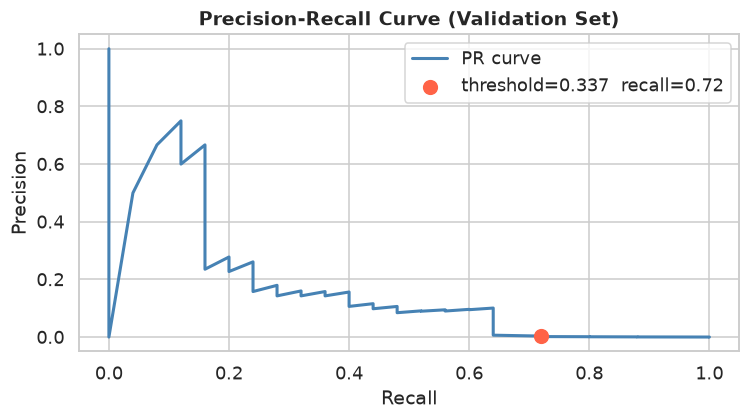

In [22]:
# 6b. Decision threshold calibration
#
# With ROC-AUC ~0.97 the model ranks anomalies well; the problem is threshold
# selection. We use the ROC curve to find the highest threshold (best precision)
# that still achieves recall >= TARGET_RECALL on the validation set.
from sklearn.metrics import roc_curve as _roc_curve
from sklearn.metrics import precision_score as _ps, recall_score as _rs

_, X_val, _, y_val = train_test_split(
    X_train, y_train, test_size=0.2, stratify=y_train, random_state=SEED)

y_val_proba = pt_xgb.predict_proba(X_val)[:, 1]
prec_arr, rec_arr, thr_arr = precision_recall_curve(y_val, y_val_proba)

fpr_v, tpr_v, roc_thr_v = _roc_curve(y_val, y_val_proba)

TARGET_RECALL = 0.70  # minimum recall we want on the validation set

# Among all thresholds where TPR >= TARGET_RECALL, pick the highest one
# (= fewest false positives = best precision while still meeting recall target)
valid = [
    (tpr, fpr, float(t))
    for tpr, fpr, t in zip(tpr_v, fpr_v, roc_thr_v)
    if tpr >= TARGET_RECALL
]
if valid:
    _best_tpr, _best_fpr, DECISION_THRESHOLD = min(valid, key=lambda x: x[1])
else:
    print(f'[NOTE] recall {TARGET_RECALL:.0%} not achievable; using max-recall threshold')
    DECISION_THRESHOLD = float(roc_thr_v[int(np.argmax(tpr_v))])

val_preds = (y_val_proba >= DECISION_THRESHOLD).astype(np.int8)
best_p = float(_ps(y_val, val_preds, zero_division=0))
best_r = float(_rs(y_val, val_preds, zero_division=0))

print(f'Decision threshold   : {DECISION_THRESHOLD:.4f}')
print(f'Validation precision : {best_p:.4f}')
print(f'Validation recall    : {best_r:.4f}')

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(rec_arr, prec_arr, color='steelblue', lw=2, label='PR curve')
ax.scatter([best_r], [best_p], color='tomato', s=80, zorder=5,
           label=f'threshold={DECISION_THRESHOLD:.3f}  recall={best_r:.2f}')
ax.set_xlabel('Recall'); ax.set_ylabel('Precision')
ax.set_title('Precision-Recall Curve (Validation Set)', fontweight='bold')
ax.legend(); plt.tight_layout(); plt.show()

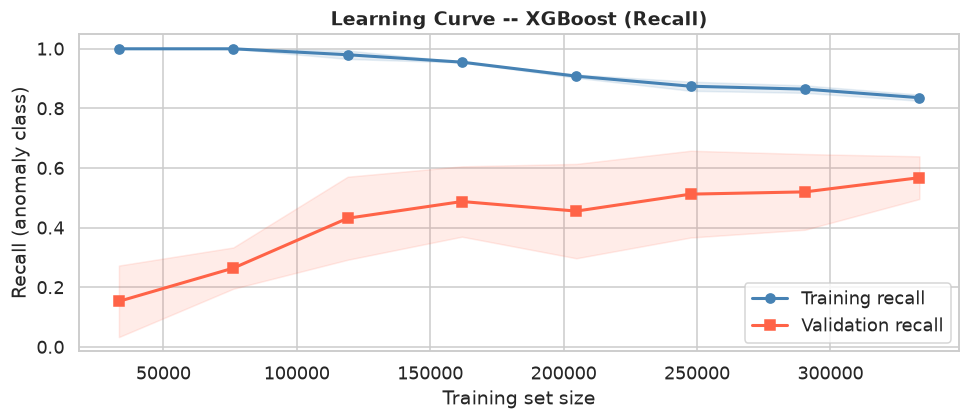

Final training recall  : 0.8361
Final validation recall: 0.5678
Gap                    : 0.2683  -- possible overfitting


In [23]:
# 6c. Learning curve -- training score vs validation score
from sklearn.model_selection import learning_curve

lc_sizes, lc_train, lc_val = learning_curve(
    xgb.XGBClassifier(**CV_PARAMS),
    X_cv, y_cv,
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED),
    scoring='recall',
    train_sizes=np.linspace(0.1, 1.0, 8),
    n_jobs=1,
)

tr_mean, tr_std = lc_train.mean(axis=1), lc_train.std(axis=1)
va_mean, va_std = lc_val.mean(axis=1),   lc_val.std(axis=1)

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(lc_sizes, tr_mean, 'o-', color='steelblue', lw=2, label='Training recall')
ax.fill_between(lc_sizes, tr_mean - tr_std, tr_mean + tr_std, alpha=0.12, color='steelblue')
ax.plot(lc_sizes, va_mean, 's-', color='tomato', lw=2, label='Validation recall')
ax.fill_between(lc_sizes, va_mean - va_std, va_mean + va_std, alpha=0.12, color='tomato')
ax.set_xlabel('Training set size')
ax.set_ylabel('Recall (anomaly class)')
ax.set_title('Learning Curve -- XGBoost (Recall)', fontweight='bold')
ax.legend()
plt.tight_layout()
plt.show()

gap = abs(float(tr_mean[-1]) - float(va_mean[-1]))
print(f'Final training recall  : {tr_mean[-1]:.4f}')
print(f'Final validation recall: {va_mean[-1]:.4f}')
print(f'Gap                    : {gap:.4f}  '
      + ('-- possible overfitting' if gap > 0.10 else '-- model generalises well'))

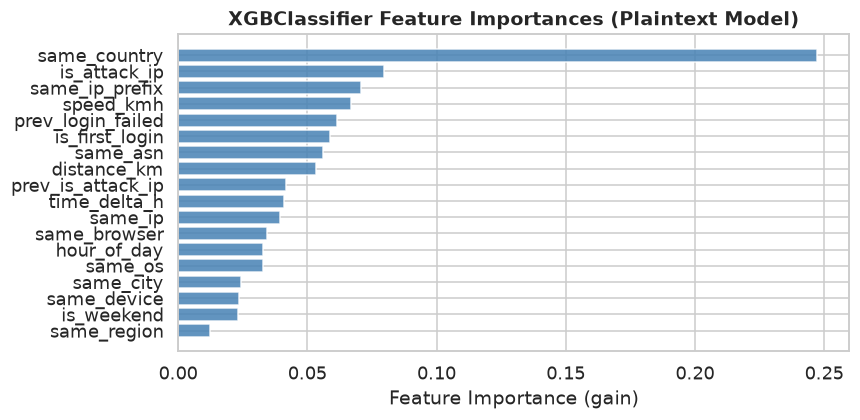

Feature importances (descending):
  same_country           0.2474  █████████████████████████████████████████████████
  is_attack_ip           0.0795  ███████████████
  same_ip_prefix         0.0707  ██████████████
  speed_kmh              0.0669  █████████████
  prev_login_failed      0.0616  ████████████
  is_first_login         0.0589  ███████████
  same_asn               0.0562  ███████████
  distance_km            0.0532  ██████████
  prev_is_attack_ip      0.0418  ████████
  time_delta_h           0.0411  ████████
  same_ip                0.0396  ███████
  same_browser           0.0344  ██████
  hour_of_day            0.0328  ██████
  same_os                0.0327  ██████
  same_city              0.0242  ████
  same_device            0.0237  ████
  is_weekend             0.0231  ████
  same_region            0.0124  ██


In [24]:
# 6c. Feature importance (plaintext model — gain)
importances = pt_xgb.feature_importances_
sorted_idx  = np.argsort(importances)[::-1]

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(
    [FEATURE_COLS[i] for i in sorted_idx[::-1]],
    importances[sorted_idx[::-1]],
    color='steelblue', alpha=0.85,
)
ax.set_xlabel('Feature Importance (gain)')
ax.set_title('XGBClassifier Feature Importances (Plaintext Model)', fontweight='bold')
plt.tight_layout(); plt.show()

print('Feature importances (descending):')
for i in sorted_idx:
    bar  = chr(9608) * max(1, int(importances[i] * 200))
    print(f'  {FEATURE_COLS[i]:<22} {importances[i]:.4f}  {bar}')

## VII. Testing

The held-out test set (most recent 20% of login pairs) is used for final evaluation across
three inference modes:

| Mode | Model | Privacy |
|------|-------|---------|
| **Plaintext** | `xgboost.XGBClassifier` | None — accuracy ceiling |
| **FHE-Simulate** | `concrete.ml.sklearn.XGBClassifier` (clear data) | None — quantisation accuracy gap |
| **FHE-Execute** | `concrete.ml.sklearn.XGBClassifier` (encrypted) | Full |

FHE-Simulate runs the quantised circuit on unencrypted data.  Any accuracy gap versus Plaintext
reflects solely **6-bit quantisation error**, not encryption noise.

FHE-Execute performs true homomorphic inference.  Due to latency (several seconds per sample),
it is evaluated on a small balanced subset.

=== 7a. Plaintext XGBClassifier -- Full Test Set ===
Decision threshold : 0.3374

Plaintext XGBoost
                Precision     Recall         F1
───────────────────────────────────────────────
Normal             1.0000     0.9989     0.9995
Anomaly            0.0010     0.3125     0.0021
───────────────────────────────────────────────
Macro avg          0.5005     0.6557     0.5008

Accuracy : 0.9989

ROC-AUC  : 0.9729
PR-AUC   : 0.0234
Latency  : 0.54 µs/sample


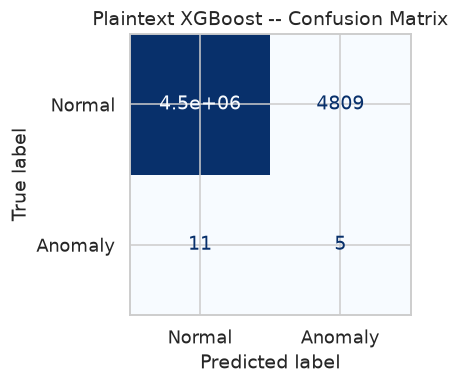

In [25]:
# 7a. Plaintext XGBClassifier -- full test set

def classification_table(y_true, y_pred, title=''):
    """Print per-class + macro Precision / Recall / F1 + overall Accuracy."""
    from sklearn.metrics import precision_recall_fscore_support, accuracy_score
    acc = accuracy_score(y_true, y_pred)
    w   = 10
    if title:
        print(f'\n{title}')
    print(f'{"":14} {"Precision":>{w}} {"Recall":>{w}} {"F1":>{w}}')
    print('─' * (14 + w * 3 + 3))
    for label, name in [(0, 'Normal'), (1, 'Anomaly')]:
        p, r, f, _ = precision_recall_fscore_support(
            y_true, y_pred, labels=[label], zero_division=0)
        print(f'{name:<14} {p[0]:>{w}.4f} {r[0]:>{w}.4f} {f[0]:>{w}.4f}')
    p_m, r_m, f_m, _ = precision_recall_fscore_support(
        y_true, y_pred, average='macro', zero_division=0)
    print('─' * (14 + w * 3 + 3))
    print(f'{"Macro avg":<14} {p_m:>{w}.4f} {r_m:>{w}.4f} {f_m:>{w}.4f}')
    print(f'\nAccuracy : {acc:.4f}')

print('=== 7a. Plaintext XGBClassifier -- Full Test Set ===')
print(f'Decision threshold : {DECISION_THRESHOLD:.4f}')
t0       = time.time()
pt_proba = pt_xgb.predict_proba(X_test)[:, 1]
pt_preds = (pt_proba >= DECISION_THRESHOLD).astype(np.int8)
pt_us    = (time.time() - t0) / len(X_test) * 1e6
pt_auc   = roc_auc_score(y_test, pt_proba)
pt_ap    = average_precision_score(y_test, pt_proba)

classification_table(y_test, pt_preds, 'Plaintext XGBoost')
print(f'\nROC-AUC  : {pt_auc:.4f}')
print(f'PR-AUC   : {pt_ap:.4f}')
print(f'Latency  : {pt_us:.2f} µs/sample')

fig, ax = plt.subplots(figsize=(4, 4))
ConfusionMatrixDisplay(
    confusion_matrix(y_test, pt_preds),
    display_labels=['Normal', 'Anomaly'],
).plot(ax=ax, colorbar=False, cmap='Blues')
ax.set_title('Plaintext XGBoost -- Confusion Matrix')
plt.tight_layout(); plt.show()

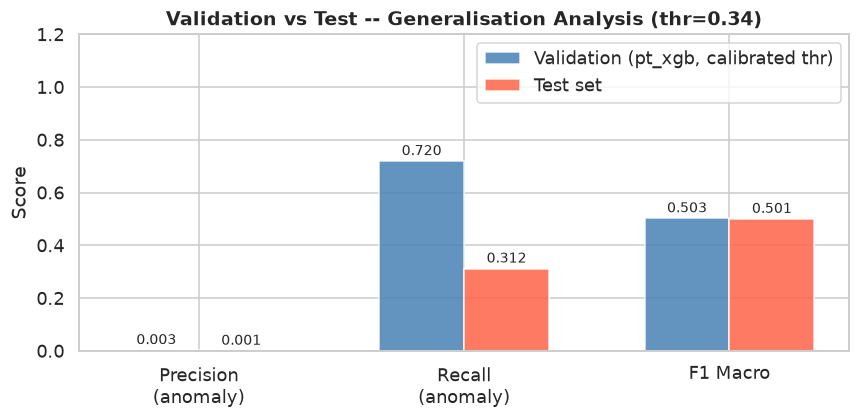

Validation F1 Macro : 0.5031
Test       F1 Macro : 0.5008
Gap                 : 0.0023  — model generalises well


In [26]:
# 7b. Validation vs Test comparison

# Both val and test metrics use DECISION_THRESHOLD for a like-for-like comparison.
# Val metrics are on a subset pt_xgb was trained on (slightly optimistic),
# but any remaining gap still indicates overfitting.
from sklearn.metrics import precision_score, recall_score, f1_score as f1

val_preds = (y_val_proba >= DECISION_THRESHOLD).astype(np.int8)
val_p  = precision_score(y_val, val_preds, zero_division=0)
val_r  = recall_score(y_val,    val_preds, zero_division=0)
val_f  = f1(y_val,              val_preds, average='macro', zero_division=0)

test_p = precision_score(y_test, pt_preds, zero_division=0)
test_r = recall_score(y_test,    pt_preds, zero_division=0)
test_f = f1(y_test,              pt_preds, average='macro', zero_division=0)

metrics  = ['Precision\n(anomaly)', 'Recall\n(anomaly)', 'F1 Macro']
val_vals  = [val_p,  val_r,  val_f]
test_vals = [test_p, test_r, test_f]

x = np.arange(len(metrics)); w = 0.32
fig, ax = plt.subplots(figsize=(8, 4))
b1 = ax.bar(x - w/2, val_vals,  w, label='Validation (pt_xgb, calibrated thr)', color='steelblue', alpha=0.85)
b2 = ax.bar(x + w/2, test_vals, w, label='Test set',            color='tomato',    alpha=0.85)
for bar, v in zip(list(b1) + list(b2), val_vals + test_vals):
    ax.text(bar.get_x() + bar.get_width()/2, v + 0.01, f'{v:.3f}',
            ha='center', va='bottom', fontsize=9)
ax.set_xticks(x); ax.set_xticklabels(metrics)
ax.set_ylim(0, 1.2); ax.set_ylabel('Score')
ax.set_title(f'Validation vs Test -- Generalisation Analysis (thr={DECISION_THRESHOLD:.2f})', fontweight='bold')
ax.legend()
plt.tight_layout(); plt.show()

gap = abs(val_f - test_f)
print(f'Validation F1 Macro : {val_f:.4f}')
print(f'Test       F1 Macro : {test_f:.4f}')
print(f'Gap                 : {gap:.4f}  '
      + ('— possible overfitting' if gap > 0.10 else '— model generalises well'))

In [ ]:
# 7c. FHE-Simulate -- full test set
print('=== 7c. FHE-Simulate -- Full Test Set ===')
print(f'Decision threshold : {DECISION_THRESHOLD:.4f}')
t0        = time.time()
sim_proba = fhe_xgb.predict_proba(X_test, fhe='simulate')[:, 1]
sim_preds = (sim_proba >= DECISION_THRESHOLD).astype(np.int8)
sim_us    = (time.time() - t0) / len(X_test) * 1e6

classification_table(y_test, sim_preds, 'FHE-Simulate')
print(f'\nLatency                  : {sim_us:.2f} µs/sample')
print(f'PT <-> Simulate agreement: {(pt_preds == sim_preds).mean()*100:.2f}%')

=== 7c. FHE-Simulate -- Full Test Set ===
Decision threshold : 0.3374


In [ ]:
# 7d. FHE-Execute -- balanced sample
# Same N_EXEC samples are reused in cc22 for the fair plaintext/FHE comparison.
N_EXEC   = 20
rng_e    = np.random.default_rng(SEED)
att_idx  = np.where(y_test == 1)[0]
nor_idx  = np.where(y_test == 0)[0]
n_att    = min(len(att_idx), N_EXEC // 2)
n_nor    = N_EXEC - n_att
exec_idx = np.concatenate([
    rng_e.choice(att_idx, n_att, replace=False),
    rng_e.choice(nor_idx, n_nor, replace=False),
])
rng_e.shuffle(exec_idx)

X_exec = X_test[exec_idx]
y_exec = y_test[exec_idx]
print(f'FHE-execute sample: {N_EXEC} rows  '
      f'(anomalies: {int(y_exec.sum())}, normal: {int((y_exec==0).sum())})
')

# Use predict_proba so DECISION_THRESHOLD can be applied consistently
# across all inference modes in the comparison cell.
exec_probas, exec_ms = [], []
for i, x in enumerate(X_exec):
    t0    = time.time()
    proba = fhe_xgb.predict_proba(x.reshape(1, -1), fhe='execute')
    ms    = (time.time() - t0) * 1000
    exec_probas.append(float(proba[0, 1]))
    exec_ms.append(ms)
    if (i + 1) % 5 == 0 or i == 0:
        pred_label = int(proba[0, 1] >= DECISION_THRESHOLD)
        print(f'  [{i+1:2d}/{N_EXEC}]  {ms:6.0f} ms  '
              f'pred={pred_label}  true={int(y_exec[i])}')

exec_probas  = np.array(exec_probas)
exec_preds   = (exec_probas >= DECISION_THRESHOLD).astype(np.int8)
mean_exec_ms = float(np.mean(exec_ms))

print(f'
Mean FHE-execute latency : {mean_exec_ms:.0f} ms/sample')

In [ ]:
# 7e. Inference mode comparison -- fair evaluation on the same N_EXEC samples
#
# All three modes are evaluated on the identical X_exec subset so that
# accuracy differences reflect the model (quantisation / encryption noise),
# not sample selection. The same DECISION_THRESHOLD is applied to all.
print('=== 7e. Inference Mode Comparison (N={N_EXEC}, same samples) ===')
print(f'Decision threshold : {DECISION_THRESHOLD:.4f}
')

# Plaintext on X_exec
pt_exec_proba  = pt_xgb.predict_proba(X_exec)[:, 1]
pt_exec_preds  = (pt_exec_proba  >= DECISION_THRESHOLD).astype(np.int8)

# FHE-Simulate on X_exec
sim_exec_proba = fhe_xgb.predict_proba(X_exec, fhe='simulate')[:, 1]
sim_exec_preds = (sim_exec_proba >= DECISION_THRESHOLD).astype(np.int8)

# FHE-Execute on X_exec (probas already computed in cc21)
classification_table(y_exec, pt_exec_preds,  'Plaintext XGBoost')
classification_table(y_exec, sim_exec_preds, 'FHE-Simulate')
classification_table(y_exec, exec_preds,     'FHE-Execute')

pt_sim_agree  = (pt_exec_preds  == sim_exec_preds).mean() * 100
pt_fhe_agree  = (pt_exec_preds  == exec_preds).mean()     * 100
sim_fhe_agree = (sim_exec_preds == exec_preds).mean()     * 100
print(f'
Agreement PT  <-> Simulate : {pt_sim_agree:.1f}%')
print(f'Agreement PT  <-> Execute  : {pt_fhe_agree:.1f}%')
print(f'Agreement Sim <-> Execute  : {sim_fhe_agree:.1f}%')

# --- Latency comparison bar chart ---
t0 = time.time(); pt_xgb.predict_proba(X_exec)
pt_us_e  = (time.time() - t0) / N_EXEC * 1e6
t0 = time.time(); fhe_xgb.predict_proba(X_exec, fhe='simulate')
sim_us_e = (time.time() - t0) / N_EXEC * 1e6

fig, ax = plt.subplots(figsize=(7, 3.5))
modes   = ['Plaintext', 'FHE-Simulate', 'FHE-Execute']
latency = [pt_us_e,     sim_us_e,       mean_exec_ms * 1000]
colors  = ['steelblue', 'darkorange',   'seagreen']
bars    = ax.bar(modes, latency, color=colors, alpha=0.85, width=0.5)
for bar, v in zip(bars, latency):
    label = f'{v:.0f} µs' if v < 1e6 else f'{v/1e6:.1f} s'
    ax.text(bar.get_x() + bar.get_width()/2, v * 1.05, label,
            ha='center', va='bottom', fontsize=9)
ax.set_yscale('log')
ax.set_ylabel('Latency per sample (µs, log scale)')
ax.set_title('Inference Latency by Mode', fontweight='bold')
plt.tight_layout(); plt.show()
print(f'FHE-Execute overhead vs plaintext: ~{mean_exec_ms*1000/max(pt_us_e,1e-9):.0f}x')

## VIII. Artifact Export

All artifacts are written to the `models/` directory mounted by the FastAPI service container.
The service reloads them automatically on startup (no container rebuild needed).

| Artifact | Consumer |
|----------|----------|
| `feature_cols.json` | `ml_model.py` — enforces correct feature ordering at inference time |
| `scaler.joblib` | `ml_model.py` — normalises raw input features |
| `plaintext_model.joblib` | `ml_model.py` — fast plaintext inference |
| `fhe_model/` | `FHEModelServer` + `FHEModelClient` — true FHE inference |
| `fhe_model/sklearn_model.joblib` | `ml_model.py` — FHE-simulate mode |

In [ ]:
# 8. Save all artifacts
from concrete.ml.deployment import FHEModelDev

(MODELS_DIR / 'feature_cols.json').write_text(json.dumps(FEATURE_COLS))
joblib.dump(scaler,  MODELS_DIR / 'scaler.joblib')
joblib.dump(pt_xgb,  MODELS_DIR / 'plaintext_model.joblib')

fhe_dev = FHEModelDev(path_dir=str(MODELS_DIR / 'fhe_model'), model=fhe_xgb)
fhe_dev.save()

joblib.dump(fhe_xgb, MODELS_DIR / 'fhe_model' / 'sklearn_model.joblib')

print('=== Saved Artifacts ===')
for f in sorted(MODELS_DIR.rglob('*')):
    if f.is_file():
        size_kb = f.stat().st_size // 1024
        print(f'  {str(f.relative_to(MODELS_DIR)):<50} {size_kb:>6} KB')

print('\nRestart the service-provider container to load the updated models.')